# Credit card fraud detection

## 1. Problem definition and objectives

Sinh viên: Phạm Văn Tuấn Kiệt — mssv: 23010881

Bài toán là Binary Classification: dự đoán nhãn `is_fraud` của giao dịch (`0`: không gian lận, `1`: gian lận).

Trong phạm vi đồ án, model hỗ trợ tạo cảnh báo để kiểm tra giao dịch. Luồng xử lý là:

**Transaction → preprocessing → fraud score → threshold → alert**


### Evaluation objectives

Fraud là lớp thiểu số nên Accuracy không phải metric chính. Ta quan tâm hai loại sai sót: **FP** là giao dịch hợp lệ bị cảnh báo nhầm; **FN** là giao dịch Fraud bị bỏ sót.

| Metric | Ý nghĩa trong bài toán |
|---|---|
| Average Precision (AP) | Đánh giá khả năng xếp hạng Fraud trên Precision–Recall Curve; cao hơn là tốt hơn. |
| Precision | Trong các cảnh báo, bao nhiêu phần là Fraud? Precision cao giúp giảm cảnh báo nhầm. |
| Recall | Trong các giao dịch Fraud, model phát hiện được bao nhiêu phần? Recall cao giúp giảm bỏ sót. |
| F1-score | Trung bình điều hòa của Precision và Recall tại một threshold; dùng bổ sung để tóm tắt trade-off. |


### Experimental workflow
1. Kiểm tra dữ liệu; chia theo thời gian thành Train / Validation / Test = 70/15/15
2. Làm EDA trên Train, xây dựng features và fit preprocessing chỉ bằng dữ liệu huấn luyện tương ứng.
3. Huấn luyện Logistic Regression, Random Forest và XGBoost; dùng AP trên Validation để so sánh khả năng xếp hạng và chọn model.
4. Chọn threshold trên Validation, cố định model và threshold trước khi đánh giá Test; diễn giải kết quả bằng TP, FP, FN và minh họa luồng cảnh báo.



## 2. Libraries and configuration

In [354]:
import importlib.util
import subprocess
import sys

required_packages = {
    "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
    "seaborn": "seaborn", "sklearn": "scikit-learn",
    "xgboost": "xgboost", "jinja2": "jinja2",
}
missing = [package for module, package in required_packages.items()
           if importlib.util.find_spec(module) is None]

if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
print("Đã sẵn sàng các thư viện cần thiết.")


Đã sẵn sàng các thư viện cần thiết.


In [355]:
from pathlib import Path
from importlib.metadata import version
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import xgboost
from xgboost import XGBClassifier

runtime_versions = {"Python": platform.python_version()}
runtime_versions.update({package: version(package)
                         for package in required_packages.values()})
tested_versions = {
    "Python": "3.11.9", "numpy": "2.4.6", "pandas": "2.3.3",
    "matplotlib": "3.11.2", "seaborn": "0.13.2", "scikit-learn": "1.9.1",
    "xgboost": "3.2.0", "jinja2": "3.1.6",
}
display(pd.DataFrame({"Current": runtime_versions, "Verified": tested_versions}))


,Current,Verified
Python,3.11.9,3.11.9
numpy,2.4.6,2.4.6
pandas,2.3.3,2.3.3
matplotlib,3.11.2,3.11.2
seaborn,0.13.2,0.13.2
scikit-learn,1.9.1,1.9.1
xgboost,3.2.0,3.2.0
jinja2,3.1.6,3.1.6


In [356]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

TARGET_COL = "is_fraud"
ID_COL = "trans_num"
TRANSACTION_TIME_COL = "trans_date_trans_time"
DATE_OF_BIRTH_COL = "dob"

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (10, 6),
                     "axes.titlesize": 13, "axes.labelsize": 11})


## 3. Data loading

In [357]:
DATA_PATH = Path("credit_card_fraud.csv")  # Có thể đổi sang đường dẫn đầy đủ.

if not DATA_PATH.is_file():
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(
            f"Không tìm thấy {DATA_PATH.resolve()}. Hãy sửa DATA_PATH."
        ) from None

    print("Chọn một file CSV chứa dữ liệu giao dịch.")
    uploaded = files.upload()
    csv_paths = [Path(name) for name in uploaded if name.lower().endswith(".csv")]
    if len(csv_paths) != 1:
        raise ValueError("Hãy upload đúng một CSV hoặc sửa DATA_PATH rồi chạy lại.")
    DATA_PATH = csv_paths[0]

print(f"Dataset: {DATA_PATH.resolve()}")


Dataset: D:\4Term_1_2026_2027\Data Mining\03_Project\credit_card_fraud.csv


In [358]:
df = pd.read_csv(DATA_PATH)

required_columns = {
    "trans_date_trans_time", "trans_num", "is_fraud", "amt", "dob",
    "merchant", "category", "city", "state", "city_pop", "job",
    "lat", "long", "merch_lat", "merch_long",
}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"CSV thiếu các cột: {sorted(missing_columns)}")

print(f"Đã đọc {len(df):,} giao dịch, {df.shape[1]} cột.")


numeric_inputs = ["amt", "city_pop", "lat", "long", "merch_lat", "merch_long"]
non_numeric = [col for col in numeric_inputs if not pd.api.types.is_numeric_dtype(df[col])]
if non_numeric:
    raise ValueError(f"Các cột phải chứa số: {non_numeric}. Hãy kiểm tra định dạng CSV.")

Đã đọc 339,607 giao dịch, 15 cột.


In [359]:
display(df.head())

,trans_date_trans_time,merchant,category,amt,city,state,lat,long,city_pop,job,dob,trans_num,merch_lat,merch_long,is_fraud
0,2019-01-01 00:00:44,"Heller, Gutmann and Zieme",grocery_pos,107.2300,Orient,WA,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,49.1590,-118.1865,0
1,2019-01-01 00:00:51,Lind-Buckridge,entertainment,220.1100,Malad City,ID,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,43.1507,-112.1545,0
2,2019-01-01 00:07:27,Kiehn Inc,grocery_pos,96.2900,Grenada,CA,41.6125,-122.5258,589,Systems analyst,1945-12-21,413636e759663f264aae1819a4d4f231,41.6575,-122.2303,0
3,2019-01-01 00:09:03,Beier-Hyatt,shopping_pos,7.7700,High Rolls Mountain Park,NM,32.9396,-105.8189,899,Naval architect,1967-08-30,8a6293af5ed278dea14448ded2685fea,32.8633,-106.5202,0
4,2019-01-01 00:21:32,Bruen-Yost,misc_pos,6.8500,Freedom,WY,43.0172,-111.0292,471,"Education officer, museum",1967-08-02,f3c43d336e92a44fc2fb67058d5949e3,43.7537,-111.4549,0


In [360]:
column_summary = df.dtypes.astype(str).rename_axis("Column").to_frame("Dtype")
display(column_summary)


,Dtype
Column,
trans_date_trans_time,object
merchant,object
category,object
amt,float64
city,object
state,object
lat,float64
long,float64
city_pop,int64


## 4. Data Quality


In [361]:
text_columns = df.select_dtypes(include=["object", "string"]).columns
blank_counts = df[text_columns].apply(
    lambda column: column.astype("string").str.strip().eq("").sum()
)
missing_summary = pd.DataFrame({
    "Missing": df.isna().sum(),
    "Missing (%)": df.isna().mean() * 100,
    "Blank": blank_counts.reindex(df.columns, fill_value=0),
})
display(missing_summary)


,Missing,Missing (%),Blank
trans_date_trans_time,0,0.0000,0
merchant,0,0.0000,0
category,0,0.0000,0
amt,0,0.0000,0
city,0,0.0000,0
state,0,0.0000,0
lat,0,0.0000,0
long,0,0.0000,0
city_pop,0,0.0000,0
job,0,0.0000,0


In [362]:
duplicate_rows = int(df.duplicated().sum())
duplicate_transaction_ids = int(df[ID_COL].duplicated().sum())
print(f"Dòng trùng hoàn toàn: {duplicate_rows:,}")
print(f"Mã giao dịch lặp sau lần đầu: {duplicate_transaction_ids:,}")


Dòng trùng hoàn toàn: 0
Mã giao dịch lặp sau lần đầu: 0


In [363]:
observed_target_values = set(df[TARGET_COL].dropna().unique())
invalid_target_values = observed_target_values - {0, 1}
print("Các nhãn xuất hiện:", sorted(observed_target_values, key=str))
if df[TARGET_COL].isna().any() or invalid_target_values:
    raise ValueError("Target có giá trị thiếu hoặc ngoài 0/1; cần kiểm tra CSV.")
if observed_target_values != {0, 1}:
    raise ValueError("Dữ liệu cần có cả hai lớp Non-Fraud và Fraud.")


Các nhãn xuất hiện: [np.int64(0), np.int64(1)]


In [364]:
target_distribution = df[TARGET_COL].value_counts().reindex([0, 1]).to_frame("Count")
target_distribution.index = pd.Index(["Non-Fraud", "Fraud"], name="Class")
target_distribution["Percent (%)"] = target_distribution["Count"] / len(df) * 100
display(target_distribution)


,Count,Percent (%)
Class,,
Non-Fraud,337825,99.4753
Fraud,1782,0.5247


### Class Imbalance 


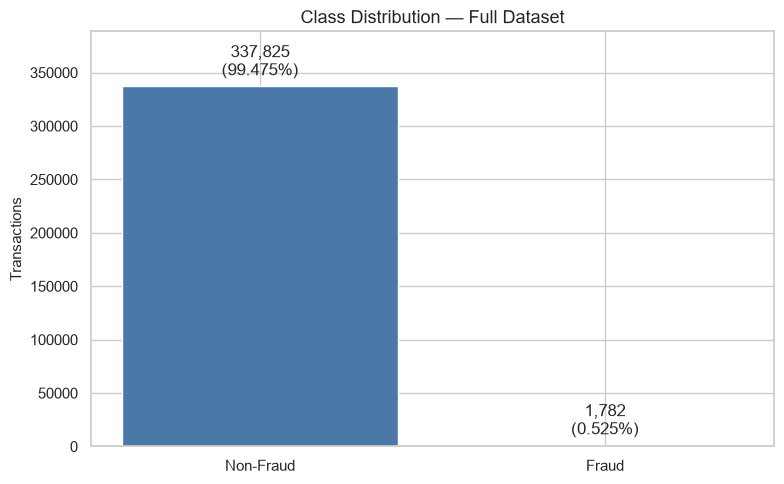

Fraud chiếm 0.525%;
Dùng AP, Precision và Recall để đánh giá.


In [365]:
class_counts = df[TARGET_COL].value_counts().reindex([0, 1], fill_value=0)
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(["Non-Fraud", "Fraud"], class_counts,
              color=["#4C78A8", "#E45756"])
labels = [f"{count:,}\n({count / len(df):.3%})" for count in class_counts]
ax.bar_label(bars, labels=labels, padding=4)
ax.set(title="Class Distribution — Full Dataset", ylabel="Transactions",
       ylim=(0, class_counts.max() * 1.15))
ax.ticklabel_format(style="plain", axis="y")
fig.tight_layout()

figure_dir = Path("outputs/figures")
figure_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_dir / "class_imbalance.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"Fraud chiếm {class_counts.loc[1] / len(df):.3%};\nDùng AP, Precision và Recall để đánh giá.")


## 5. Data Validation and anomaly checks


In [366]:
# Parse tạm để kiểm tra; không thay đổi df.
transaction_time_temp = pd.to_datetime(
    df[TRANSACTION_TIME_COL], format="%Y-%m-%d %H:%M:%S", errors="coerce"
)
date_of_birth_temp = pd.to_datetime(
    df[DATE_OF_BIRTH_COL], format="%Y-%m-%d", errors="coerce"
)
age_at_transaction = (
    (transaction_time_temp - date_of_birth_temp).dt.total_seconds()
    / (365.2425 * 24 * 60 * 60)
)


In [367]:
numeric_columns = df.select_dtypes(include=np.number).columns
checks = {
    "Transaction datetime không đọc được": transaction_time_temp.isna().sum(),
    "Ngày sinh không đọc được": date_of_birth_temp.isna().sum(),
    "Ngày sinh sau thời điểm giao dịch": (date_of_birth_temp > transaction_time_temp).sum(),
    "Amount <= 0": (df["amt"] <= 0).sum(),
    "City population <= 0": (df["city_pop"] <= 0).sum(),
    "Latitude ngoài [-90, 90]": (~df["lat"].between(-90, 90)).sum(),
    "Longitude ngoài [-180, 180]": (~df["long"].between(-180, 180)).sum(),
    "Merchant latitude ngoài [-90, 90]": (~df["merch_lat"].between(-90, 90)).sum(),
    "Merchant longitude ngoài [-180, 180]": (~df["merch_long"].between(-180, 180)).sum(),
}
validity_checks = pd.Series(checks, name="Transactions").rename_axis("Check").to_frame()
display(validity_checks)
# Đếm ô, không phải giao dịch; NaN đã được báo ở bảng Missing.
infinite_cells = int(np.isinf(df[numeric_columns]).sum().sum())



,Transactions
Check,
Transaction datetime không đọc được,0
Ngày sinh không đọc được,0
Ngày sinh sau thời điểm giao dịch,0
Amount <= 0,0
City population <= 0,0
"Latitude ngoài [-90, 90]",0
"Longitude ngoài [-180, 180]",0
"Merchant latitude ngoài [-90, 90]",0
"Merchant longitude ngoài [-180, 180]",0


In [368]:
range_values = {
    "Transaction datetime": transaction_time_temp,
    "Date of birth": date_of_birth_temp,
    "Age at transaction": age_at_transaction,
    "Transaction amount": df["amt"],
    "City population": df["city_pop"],
}
range_summary = pd.DataFrame([
    {"Variable": name, "Minimum": values.min(), "Maximum": values.max()}
    for name, values in range_values.items()
])
display(range_summary)


,Variable,Minimum,Maximum
0,Transaction datetime,2019-01-01 00:00:44,2020-12-31 23:59:24
1,Date of birth,1927-09-09 00:00:00,2001-07-26 00:00:00
2,Age at transaction,17.4352,93.3142
3,Transaction amount,1.0000,"28,948.9000"
4,City population,46,2383912


### Findings and Data Handling

In [369]:
backward_steps = int((transaction_time_temp.diff() < pd.Timedelta(0)).sum())
under_18 = int((age_at_transaction < 18).sum())
over_100 = int((age_at_transaction > 100).sum())
print(f"Timestamp đi lùi giữa hai dòng liên tiếp: {backward_steps:,} lần.")
print(f"Giao dịch có tuổi < 18: {under_18:,}; tuổi > 100: {over_100:,}.")
print(f"Khoảng tuổi quan sát: {age_at_transaction.min():.2f}–{age_at_transaction.max():.2f}.")
invalid_data = validity_checks["Transactions"].sum() > 0 or infinite_cells > 0
invalid_ids = df[ID_COL].isna().any() or df[ID_COL].astype("string").str.strip().eq("").any()
if invalid_data or invalid_ids or duplicate_rows or duplicate_transaction_ids:
    raise ValueError("Dừng trước modeling: cần xử lý giá trị không hợp lệ, mã thiếu hoặc giao dịch trùng ở nguồn CSV.")


Timestamp đi lùi giữa hai dòng liên tiếp: 1 lần.
Giao dịch có tuổi < 18: 564; tuổi > 100: 0.
Khoảng tuổi quan sát: 17.44–93.31.


## 6. Temporal Train–Validation–Test Split


In [370]:
data = df.copy()
data[TRANSACTION_TIME_COL] = pd.to_datetime(
    data[TRANSACTION_TIME_COL], format="%Y-%m-%d %H:%M:%S", errors="raise"
)
data[DATE_OF_BIRTH_COL] = pd.to_datetime(
    data[DATE_OF_BIRTH_COL], format="%Y-%m-%d", errors="raise"
)
# mergesort giữ thứ tự gốc giữa các giao dịch cùng timestamp.
data = data.sort_values(TRANSACTION_TIME_COL, kind="mergesort").reset_index(drop=True)


In [371]:
TRAIN_RATIO, VALIDATION_RATIO, TEST_RATIO = 0.70, 0.15, 0.15
assert np.isclose(TRAIN_RATIO + VALIDATION_RATIO + TEST_RATIO, 1.0)

total_rows = len(data)
train_end_index = int(total_rows * TRAIN_RATIO)
validation_end_index = int(total_rows * (TRAIN_RATIO + VALIDATION_RATIO))

train_df = data.iloc[:train_end_index].copy()
validation_df = data.iloc[train_end_index:validation_end_index].copy()
test_df = data.iloc[validation_end_index:].copy()


In [372]:
assert all(len(part) > 0 for part in [train_df, validation_df, test_df]), "Có tập rỗng."
assert len(train_df) + len(validation_df) + len(test_df) == total_rows
assert data[TRANSACTION_TIME_COL].is_monotonic_increasing, "Dữ liệu chưa đúng thứ tự thời gian."

assert train_df[TRANSACTION_TIME_COL].max() < validation_df[TRANSACTION_TIME_COL].min(), (
    "Train/Validation cùng timestamp tại ranh giới; cần điều chỉnh điểm chia."
)
assert validation_df[TRANSACTION_TIME_COL].max() < test_df[TRANSACTION_TIME_COL].min(), (
    "Validation/Test cùng timestamp tại ranh giới; cần điều chỉnh điểm chia."
)


In [373]:
def summarize_split(split_name, frame, include_target=True):
    # Không đọc nhãn Test nếu include_target=False.
    fraud = int(frame[TARGET_COL].sum()) if include_target else np.nan
    return {
        "Dataset": split_name,
        "Start Date": frame[TRANSACTION_TIME_COL].min(),
        "End Date": frame[TRANSACTION_TIME_COL].max(),
        "Transactions": len(frame),
        "Dataset Share (%)": len(frame) / len(data) * 100,
        "Fraud": fraud,
        "Non-Fraud": len(frame) - fraud,
        "Fraud Rate (%)": fraud / len(frame) * 100,
    }


In [374]:
split_summary = pd.DataFrame([
    summarize_split("Train", train_df),
    summarize_split("Validation", validation_df),
    summarize_split("Test", test_df, include_target=False),
])
display(split_summary.style.format({
    "Transactions": "{:,.0f}", "Dataset Share (%)": "{:.2f}",
    "Fraud": "{:,.0f}", "Non-Fraud": "{:,.0f}", "Fraud Rate (%)": "{:.4f}",
}, na_rep="-").hide(axis="index"))


Dataset,Start Date,End Date,Transactions,Dataset Share (%),Fraud,Non-Fraud,Fraud Rate (%)
Train,2019-01-01 00:00:44,2020-06-21 10:32:23,"237,724",70.00,"1,399","236,325",0.5885
Validation,2020-06-21 10:37:06,2020-10-02 20:08:57,"50,941",15.00,212,"50,729",0.4162
Test,2020-10-02 20:12:08,2020-12-31 23:59:24,"50,942",15.00,-,-,-


## 7. Exploratory Data Analysis



In [375]:
eda_df = train_df.copy()
eda_df["class_label"] = eda_df[TARGET_COL].map({0: "Non-Fraud", 1: "Fraud"})
eda_df["transaction_month"] = eda_df[TRANSACTION_TIME_COL].dt.to_period("M").astype(str)
eda_df["transaction_hour"] = eda_df[TRANSACTION_TIME_COL].dt.hour
eda_df["day_of_week"] = eda_df[TRANSACTION_TIME_COL].dt.day_name()

class_order = ["Non-Fraud", "Fraud"]
class_palette = {"Non-Fraud": "#4C78A8", "Fraud": "#E45756"}
overall_train_fraud_rate = eda_df[TARGET_COL].mean() * 100
print(f"Train: {len(eda_df):,} giao dịch; Fraud Rate: {overall_train_fraud_rate:.4f}%")


Train: 237,724 giao dịch; Fraud Rate: 0.5885%


In [376]:
def summarize_groups(column):
    summary = eda_df.groupby(column, observed=False)[TARGET_COL].agg(
        Transaction_Count="size", Fraud_Count="sum", Fraud_Rate="mean"
    )
    summary["Fraud_Rate"] *= 100  # Đơn vị: %.
    return summary.reset_index()


In [377]:
def save_eda_figure(fig, filename):
    output_dir = Path("outputs/figures")
    output_dir.mkdir(parents=True, exist_ok=True)
    fig.tight_layout()
    fig.savefig(output_dir / filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)


In [378]:
def plot_group_profile(summary, column, title, filename):
    height = max(4, len(summary) * 0.4 + 1.5)
    fig, axes = plt.subplots(1, 2, figsize=(16, height), sharey=True)
    bars = axes[0].barh(summary[column].astype(str), summary["Transaction_Count"], color="#4C78A8")
    axes[0].bar_label(bars, fmt="{:,.0f}", padding=3)
    axes[0].set(title="Transaction Volume", xlabel="Transactions", ylabel=column)
    axes[0].set_xlim(0, summary["Transaction_Count"].max() * 1.3)
    bars = axes[1].barh(summary[column].astype(str), summary["Fraud_Rate"], color="#E45756")
    axes[1].bar_label(bars, fmt="{:.2f}%", padding=3)
    axes[1].axvline(overall_train_fraud_rate, color="#333333", linestyle="--",
                    label=f"Train average: {overall_train_fraud_rate:.3f}%")
    axes[1].set(title="Fraud Rate", xlabel="Fraud Rate (%)")
    axes[1].set_xlim(0, max(summary["Fraud_Rate"].max(), overall_train_fraud_rate) * 1.3)
    axes[1].legend(loc="lower right", fontsize=9)
    fig.suptitle(title + " — Train")
    save_eda_figure(fig, filename)


### 7.1 Transaction Amount

In [379]:
amount_summary = eda_df.groupby("class_label", observed=True)["amt"].agg(
    ["count", "mean", "median", "std", "min", "max"]
).reindex(class_order)
display(amount_summary)


,count,mean,median,std,min,max
class_label,,,,,,
Non-Fraud,236325,68.2867,46.3700,158.9533,1.0000,"28,948.9000"
Fraud,1399,515.5777,355.1800,385.0500,2.1300,"1,371.8100"


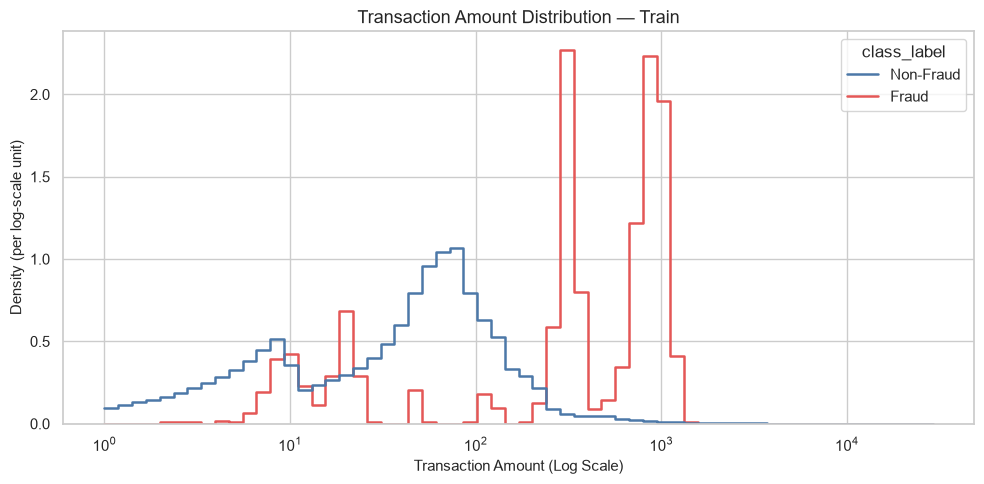

In [380]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(
    data=eda_df, x="amt", hue="class_label", hue_order=class_order,
    palette=class_palette, bins=60, stat="density", common_norm=False,
    element="step", fill=False, linewidth=1.8, log_scale=(True, False), ax=ax,
)
ax.set(title="Transaction Amount Distribution — Train",
       xlabel="Transaction Amount (Log Scale)", ylabel="Density (per log-scale unit)")
save_eda_figure(fig, "transaction_amount.png")


### 7.2 Merchant Category

In [381]:
category_summary = summarize_groups("category").sort_values("Fraud_Rate", ascending=False)
display(category_summary)


,category,Transaction_Count,Fraud_Count,Fraud_Rate
11,shopping_net,18425,290,1.5739
4,grocery_pos,23050,352,1.5271
8,misc_net,11823,172,1.4548
12,shopping_pos,21290,147,0.6905
2,gas_transport,24550,122,0.4969
9,misc_pos,13947,51,0.3657
13,travel,7141,19,0.2661
0,entertainment,17009,45,0.2646
3,grocery_net,7988,21,0.2629
10,personal_care,17072,38,0.2226


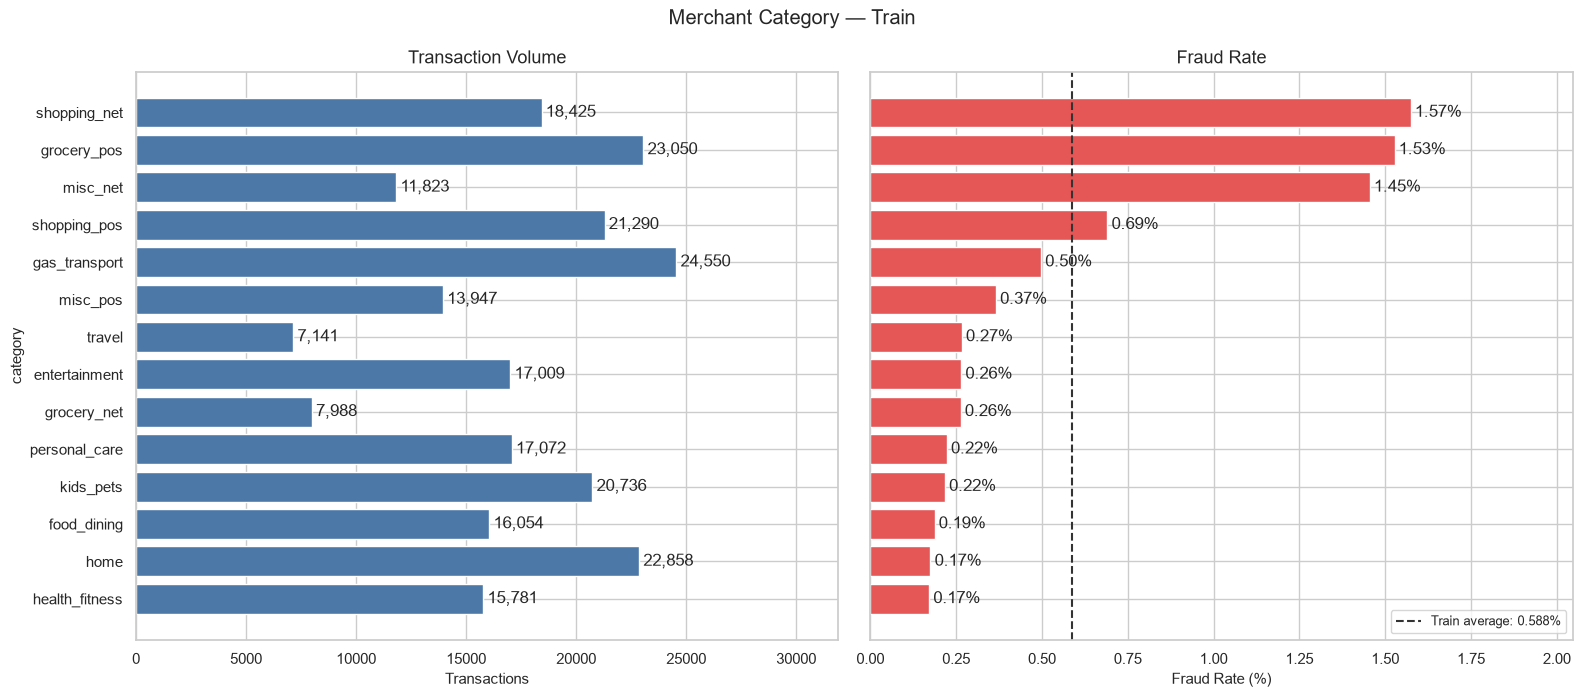

In [382]:
plot_group_profile(
    category_summary.sort_values("Fraud_Rate"), "category", "Merchant Category",
    "merchant_category.png",
)


### 7.3 Transaction Time

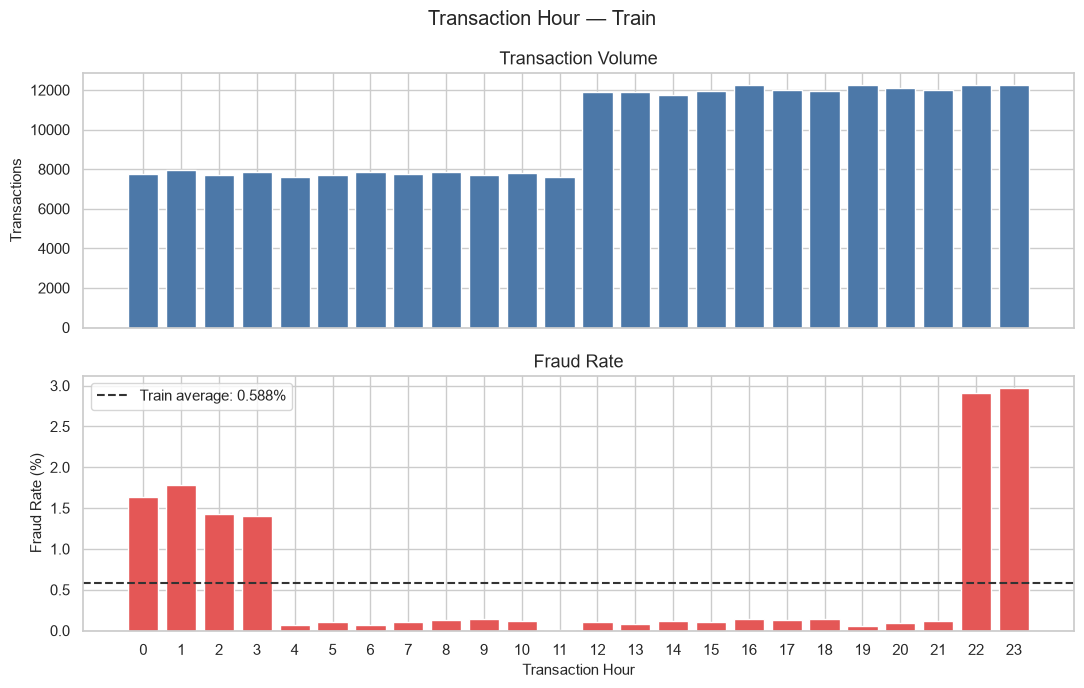

In [383]:
hourly_summary = summarize_groups("transaction_hour")
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].bar(hourly_summary["transaction_hour"], hourly_summary["Transaction_Count"], color="#4C78A8")
axes[0].set(title="Transaction Volume", ylabel="Transactions")
axes[1].bar(hourly_summary["transaction_hour"], hourly_summary["Fraud_Rate"], color="#E45756")
axes[1].axhline(overall_train_fraud_rate, color="#333333", linestyle="--",
                label=f"Train average: {overall_train_fraud_rate:.3f}%")
axes[1].set(title="Fraud Rate", xlabel="Transaction Hour", ylabel="Fraud Rate (%)")
axes[1].set_xticks(range(24))
axes[1].legend()
fig.suptitle("Transaction Hour — Train")
save_eda_figure(fig, "transaction_hour.png")


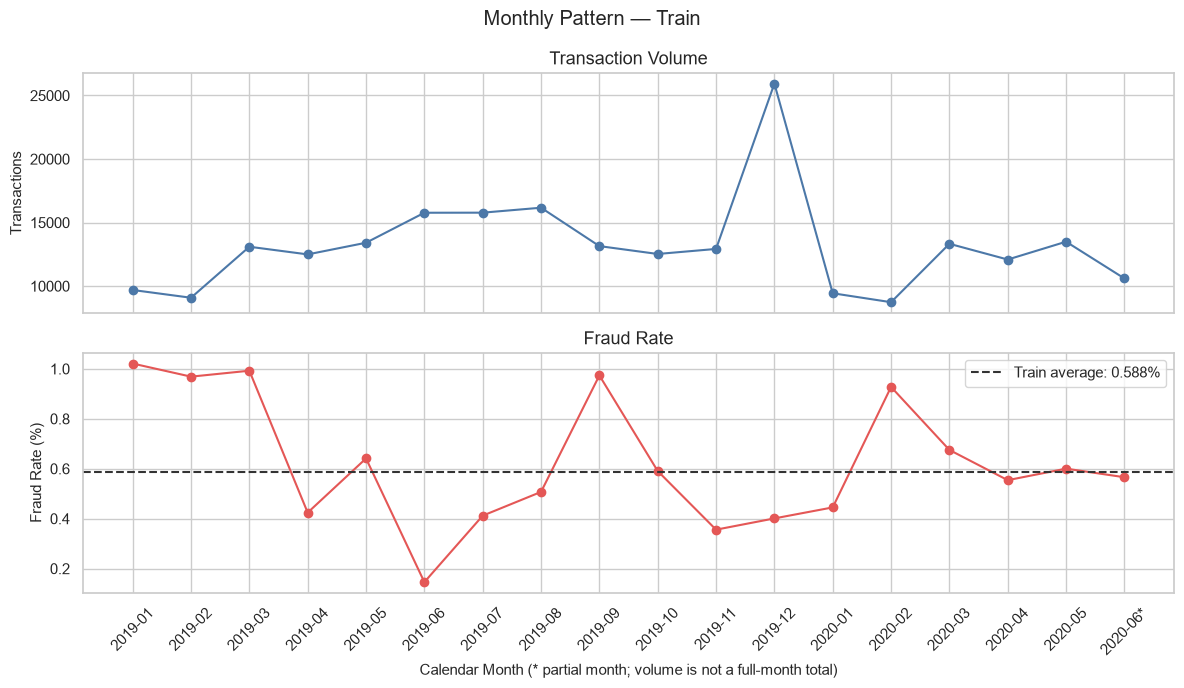

In [384]:
monthly_summary = summarize_groups("transaction_month")
# Dấu * chỉ tháng có phạm vi Train chưa bao phủ đủ ngày trong tháng.
start, end = eda_df[TRANSACTION_TIME_COL].min(), eda_df[TRANSACTION_TIME_COL].max()
partial_months = set()
if start.day > 1:
    partial_months.add(str(start.to_period("M")))
if end.day < end.days_in_month:
    partial_months.add(str(end.to_period("M")))
month_labels = [month + ("*" if month in partial_months else "")
                for month in monthly_summary["transaction_month"]]
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(month_labels, monthly_summary["Transaction_Count"],
             marker="o", color="#4C78A8")
axes[0].set(title="Transaction Volume", ylabel="Transactions")
axes[1].plot(month_labels, monthly_summary["Fraud_Rate"],
             marker="o", color="#E45756")
axes[1].axhline(overall_train_fraud_rate, color="#333333", linestyle="--",
                label=f"Train average: {overall_train_fraud_rate:.3f}%")
axes[1].set(title="Fraud Rate", ylabel="Fraud Rate (%)", xlabel="Calendar Month (* partial month; volume is not a full-month total)")
axes[1].tick_params(axis="x", labelrotation=45)
axes[1].legend()
fig.suptitle("Monthly Pattern — Train")
save_eda_figure(fig, "monthly_pattern.png")


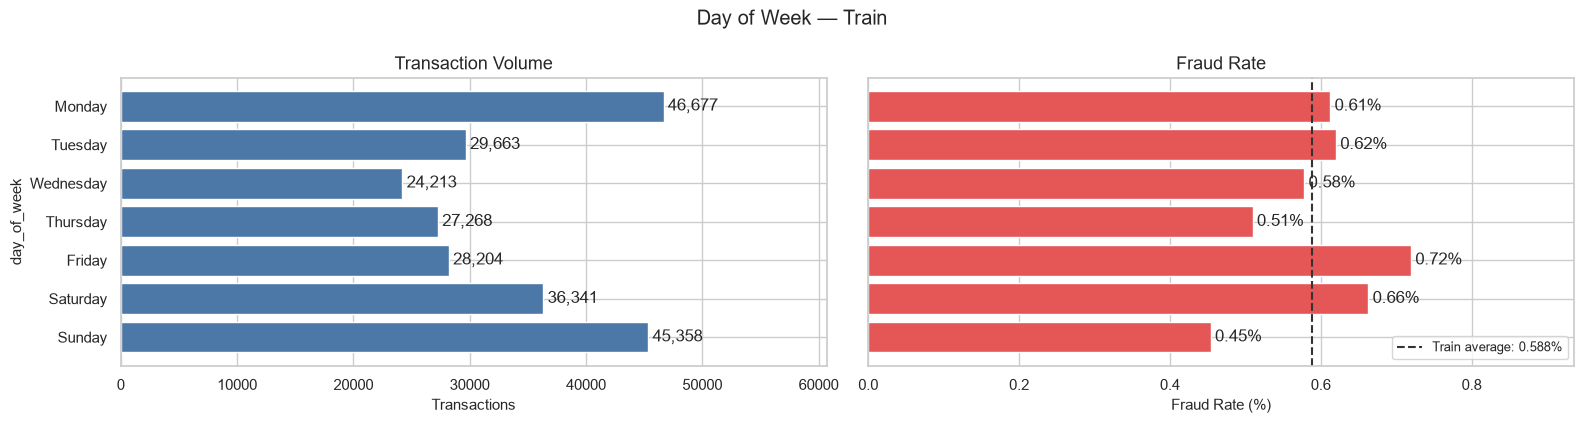

In [385]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_summary = summarize_groups("day_of_week").set_index("day_of_week").reindex(weekday_order)
plot_group_profile(weekday_summary.reset_index().iloc[::-1], "day_of_week",
                   "Day of Week", "weekday_pattern.png")


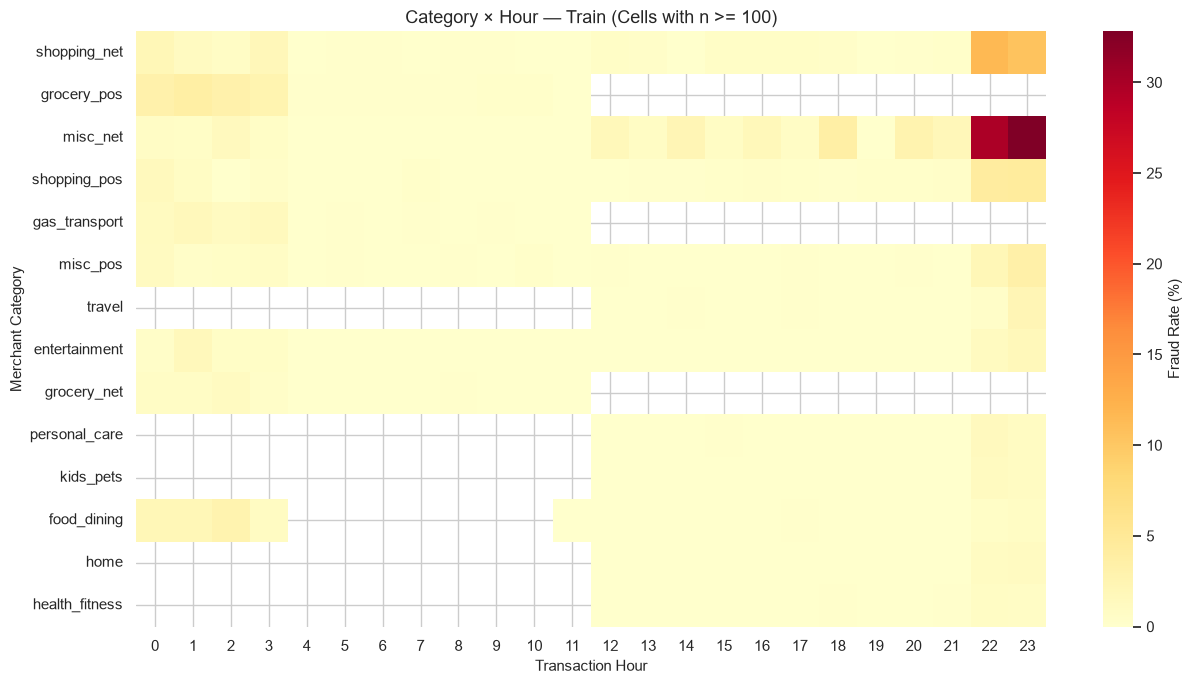

In [386]:
category_hour = eda_df.groupby(["category", "transaction_hour"], observed=True)[TARGET_COL].agg(
    Transactions="size", Fraud_Rate="mean"
)
rate_grid = category_hour["Fraud_Rate"].unstack() * 100
count_grid = category_hour["Transactions"].unstack()
rate_grid = rate_grid.where(count_grid >= 100).reindex(category_summary["category"])
fig, ax = plt.subplots(figsize=(13, 7))
sns.heatmap(rate_grid, mask=rate_grid.isna(), cmap="YlOrRd", ax=ax,
            cbar_kws={"label": "Fraud Rate (%)"})
ax.set(title="Category × Hour — Train (Cells with n >= 100)",
       xlabel="Transaction Hour", ylabel="Merchant Category")
save_eda_figure(fig, "category_hour_heatmap.png")


### 7.4 Cardholder Age

In [387]:
eda_df["cardholder_age"] = (
    (eda_df[TRANSACTION_TIME_COL] - eda_df[DATE_OF_BIRTH_COL]).dt.total_seconds()
    / (365.2425 * 24 * 60 * 60)
)
eda_df["age_group"] = pd.cut(
    eda_df["cardholder_age"], bins=[-np.inf, 18, 25, 35, 45, 55, 65, 75, np.inf],
    labels=["<18", "18–24", "25–34", "35–44", "45–54", "55–64", "65–74", "75+"], right=False,
)
age_summary = summarize_groups("age_group")
display(age_summary)


,age_group,Transaction_Count,Fraud_Count,Fraud_Rate
0,<18,564,0,0.0000
1,18–24,11466,97,0.8460
2,25–34,53314,279,0.5233
3,35–44,49197,160,0.3252
4,45–54,56787,347,0.6111
5,55–64,28715,240,0.8358
6,65–74,16462,78,0.4738
7,75+,21219,198,0.9331


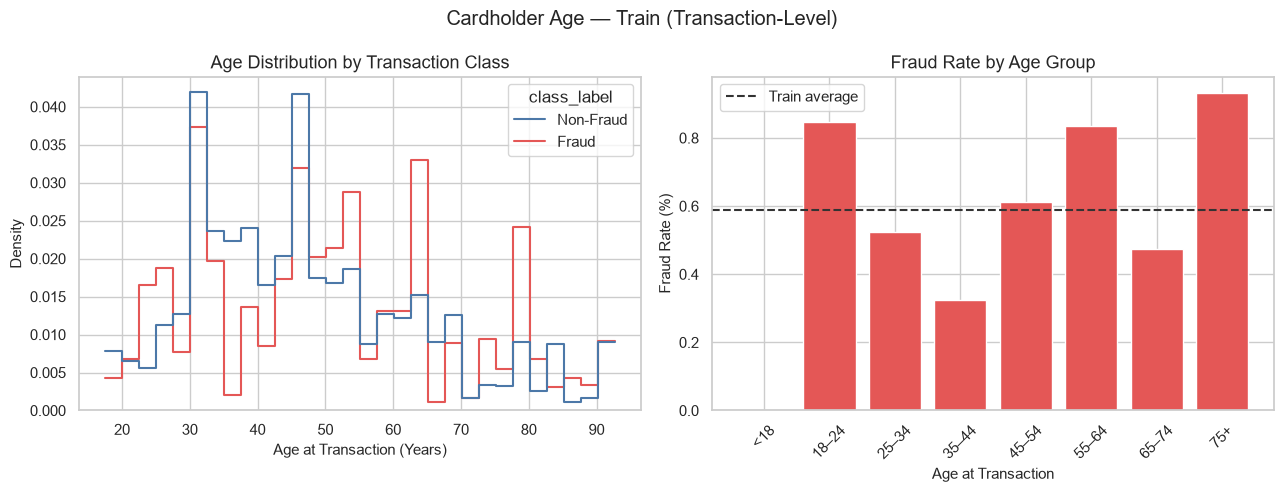

In [388]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(data=eda_df, x="cardholder_age", hue="class_label", hue_order=class_order,
             palette=class_palette, bins=30, stat="density", common_norm=False,
             element="step", fill=False, ax=axes[0])
axes[0].set(title="Age Distribution by Transaction Class", xlabel="Age at Transaction (Years)")
axes[1].bar(age_summary["age_group"].astype(str), age_summary["Fraud_Rate"], color="#E45756")
axes[1].axhline(overall_train_fraud_rate, color="#333333", linestyle="--", label="Train average")
axes[1].set(title="Fraud Rate by Age Group", xlabel="Age at Transaction", ylabel="Fraud Rate (%)")
axes[1].tick_params(axis="x", labelrotation=45)
axes[1].legend()
fig.suptitle("Cardholder Age — Train (Transaction-Level)")
save_eda_figure(fig, "cardholder_age.png")


## 8. Feature Selection



In [389]:
categorical_columns = ["merchant", "category", "city", "state", "job"]
cardinality_summary = (
    train_df[categorical_columns].nunique().sort_values(ascending=False)
    .rename_axis("Feature").to_frame("Unique Values")
)
display(cardinality_summary)


,Unique Values
Feature,
merchant,693
city,173
job,160
category,14
state,13


In [390]:
NUMERIC_FEATURES = [
    "log_amount", "cardholder_age", "log_city_population", "coordinate_distance_km",
]
CATEGORICAL_FEATURES = [
    "category", "state", "transaction_hour", "day_of_week", "month",
]
MODEL_FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
TARGET = TARGET_COL


## 9. Feature Engineering


In [391]:
def calculate_haversine_distance(lat_1, lon_1, lat_2, lon_2):
    lat_1, lon_1 = np.radians(lat_1), np.radians(lon_1)
    lat_2, lon_2 = np.radians(lat_2), np.radians(lon_2)
    delta_lat, delta_lon = lat_2 - lat_1, lon_2 - lon_1
    value = (np.sin(delta_lat / 2) ** 2
             + np.cos(lat_1) * np.cos(lat_2) * np.sin(delta_lon / 2) ** 2)
    value = np.clip(value, 0, 1)  # Kiểm soát sai số floating-point.
    angle = 2 * np.arctan2(np.sqrt(value), np.sqrt(1 - value))
    return 6371.0088 * angle  # km; dùng chung cho EDA và Feature Engineering.


In [392]:
def engineer_features(input_df):
    """Tạo 9 features, giữ index và không thay đổi dữ liệu đầu vào."""
    transaction_time = pd.to_datetime(input_df[TRANSACTION_TIME_COL], errors="raise")
    date_of_birth = pd.to_datetime(input_df[DATE_OF_BIRTH_COL], errors="raise")
    features = input_df[["category", "state"]].copy()

    features["log_amount"] = np.log1p(input_df["amt"])
    features["log_city_population"] = np.log1p(input_df["city_pop"])
    features["cardholder_age"] = (
        (transaction_time - date_of_birth).dt.total_seconds() / (365.2425 * 24 * 60 * 60)
    )
    features["transaction_hour"] = transaction_time.dt.hour
    features["day_of_week"] = transaction_time.dt.dayofweek
    features["month"] = transaction_time.dt.month
    features["coordinate_distance_km"] = calculate_haversine_distance(
        input_df["lat"], input_df["long"], input_df["merch_lat"], input_df["merch_long"]
    )
    return features[MODEL_FEATURES]


In [393]:
X_train = engineer_features(train_df)
X_validation = engineer_features(validation_df)
X_test = engineer_features(test_df)

y_train = train_df[TARGET].astype("int8").copy()
y_validation = validation_df[TARGET].astype("int8").copy()
y_test = test_df[TARGET].astype("int8").copy()


In [394]:
for X, y in [(X_train, y_train), (X_validation, y_validation), (X_test, y_test)]:
    assert X.index.equals(y.index), "Index X và y không khớp."
    assert X.columns.tolist() == MODEL_FEATURES, "Sai danh sách hoặc thứ tự features."
    assert set(y.unique()) == {0, 1}, "Mỗi tập cần có cả hai lớp."

feature_sets_summary = pd.DataFrame({
    "Dataset": ["Train", "Validation", "Test"],
    "X Shape": [str(X_train.shape), str(X_validation.shape), str(X_test.shape)],
    "y Shape": [str(y_train.shape), str(y_validation.shape), str(y_test.shape)],
    "Fraud Count": [int(y_train.sum()), int(y_validation.sum()), np.nan],
})
display(feature_sets_summary.style.format({"Fraud Count": "{:,.0f}"}, na_rep="-"))


,Dataset,X Shape,y Shape,Fraud Count
0,Train,"(237724, 9)","(237724,)","1,399"
1,Validation,"(50941, 9)","(50941,)",212
2,Test,"(50942, 9)","(50942,)",-


In [395]:
display(X_train.head())

,log_amount,cardholder_age,log_city_population,coordinate_distance_km,category,state,transaction_hour,day_of_week,month
0,4.6843,40.5320,5.0106,30.2122,grocery_pos,WA,0,1,1
1,5.3987,56.9512,8.3321,108.2062,entertainment,ID,0,1,1
2,4.5777,73.0309,6.3801,25.0591,grocery_pos,CA,0,1,1
3,2.1713,51.3412,6.8024,66.0218,shopping_pos,NM,0,1,1
4,2.0605,51.4179,6.1570,88.8311,misc_pos,WY,0,1,1


## 10. Preprocessing Pipeline


In [396]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


In [397]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])


In [398]:
try:  # Tương thích tên tham số ở các phiên bản scikit-learn.
    one_hot_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
except TypeError:
    one_hot_encoder = OneHotEncoder(handle_unknown="ignore", sparse=True)

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("one_hot", one_hot_encoder),
])


In [399]:
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, NUMERIC_FEATURES),
        ("categorical", categorical_pipeline, CATEGORICAL_FEATURES),
    ],
    remainder="drop", sparse_threshold=0.3, verbose_feature_names_out=False,
)


In [400]:
preprocessor_check = clone(preprocessor).fit(X_train)
processed_sample = preprocessor_check.transform(X_train.head())
validation_sample = preprocessor_check.transform(X_validation.head())
processed_feature_names = preprocessor_check.get_feature_names_out()

assert processed_sample.shape[1] == validation_sample.shape[1] == len(processed_feature_names)
print(f"Input features: {X_train.shape[1]} → Encoded features: {len(processed_feature_names)}")
print(f"Train sample: {processed_sample.shape}; Validation sample: {validation_sample.shape}")
print(f"Output type: {type(processed_sample).__name__}")


Input features: 9 → Encoded features: 74
Train sample: (5, 74); Validation sample: (5, 74)
Output type: csr_matrix


In [401]:
# Chỉ hiển thị 10 tên mẫu, tránh bảng dài 74 dòng.
processed_features_df = pd.DataFrame({"Processed Feature": processed_feature_names[:10]})
display(processed_features_df)
del preprocessor_check, processed_sample, validation_sample


,Processed Feature
0,log_amount
1,cardholder_age
2,log_city_population
3,coordinate_distance_km
4,category_entertainment
5,category_food_dining
6,category_gas_transport
7,category_grocery_net
8,category_grocery_pos
9,category_health_fitness


## 11. Logistic Regression



In [402]:
import time
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score,
                             recall_score, f1_score, confusion_matrix, precision_recall_curve)

trained_models, validation_probabilities, model_results = {}, {}, {}
MODEL_OUTPUT_DIR = Path("outputs/model_selection")
MODEL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_COLORS = {"Logistic Regression": "#E58B36", "Random Forest": "#39956C", "XGBoost": "#8064B0"}


In [403]:
def evaluate_at_threshold(y_true, scores, threshold):
    predicted = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predicted, labels=[0, 1]).ravel()
    return {"Threshold": float(threshold),
        "Precision": precision_score(y_true, predicted, zero_division=0),
        "Recall": recall_score(y_true, predicted, zero_division=0),
        "F1-score": f1_score(y_true, predicted, zero_division=0),
        "True Positive": int(tp), "False Positive": int(fp),
        "False Negative": int(fn), "True Negative": int(tn)}


In [404]:
def train_and_evaluate(name, classifier, preprocessing=preprocessor):
    pipeline = Pipeline([("preprocessor", clone(preprocessing)), ("classifier", classifier)])
    start = time.perf_counter()
    pipeline.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start
    scores = pipeline.predict_proba(X_validation)[:, 1]

    trained_models[name] = pipeline
    validation_probabilities[name] = scores
    model_results[name] = {
        "Model": name,
        "Average Precision": average_precision_score(y_validation, scores),
        "ROC-AUC": roc_auc_score(y_validation, scores),
        **evaluate_at_threshold(y_validation, scores, threshold=0.50),
        "Fit Seconds": fit_seconds,
    }
    print(f"{name}: AP={model_results[name]['Average Precision']:.4f}, fit={fit_seconds:.1f}s")


In [405]:
def plot_model_pr(names, filename):
    """Cùng một cách vẽ cho từng model và hình tổng hợp trên Validation."""
    fig, ax = plt.subplots(figsize=(10, 6))
    for name in names:
        precision, recall, _ = precision_recall_curve(y_validation, validation_probabilities[name])
        row = model_results[name]
        ax.plot(recall, precision, color=MODEL_COLORS[name], lw=2,
                label=f"{name} (AP={row['Average Precision']:.4f})")
        ax.scatter(row["Recall"], row["Precision"], color=MODEL_COLORS[name], s=55, zorder=3)
    ax.axhline(y_validation.mean(), color="gray", ls="--", label="No-skill reference")
    title = names[0] if len(names) == 1 else "Model Comparison"
    ax.set(title=f"{title} — Validation Precision–Recall", xlabel="Recall", ylabel="Precision",
           xlim=(0, 1.02), ylim=(0, 1.02))
    ax.text(0.02, 0.03, "Dots: threshold = 0.50", transform=ax.transAxes, fontsize=10)
    ax.legend(loc="upper right")
    plt.tight_layout()
    fig.savefig(MODEL_OUTPUT_DIR / filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

In [406]:
lr_model = LogisticRegression(
    class_weight="balanced", solver="lbfgs", max_iter=1000, tol=1e-3,
    random_state=RANDOM_STATE,
)
train_and_evaluate('Logistic Regression', lr_model)


Logistic Regression: AP=0.2382, fit=0.9s


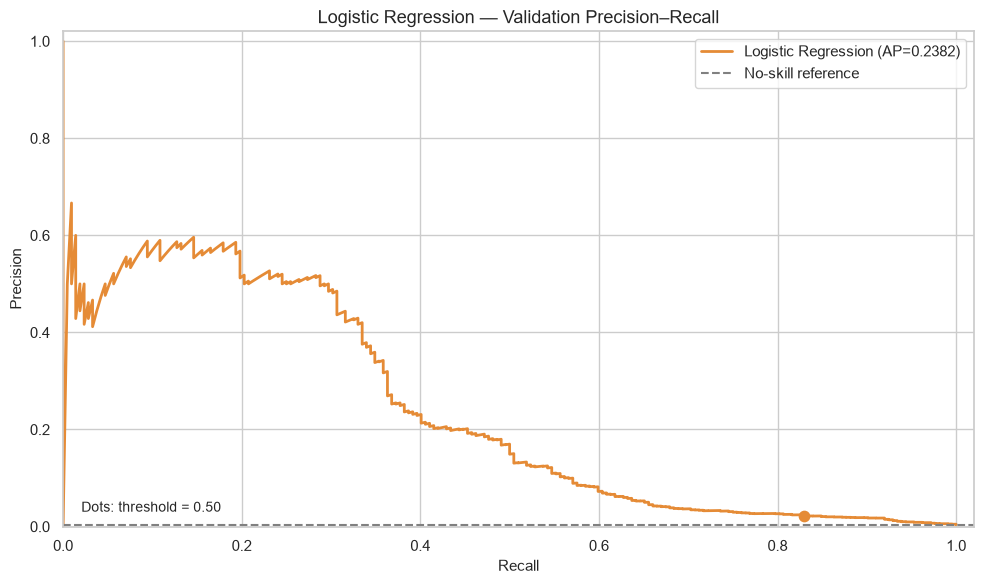

In [407]:
plot_model_pr(['Logistic Regression'], 'logistic_regression_pr.png')


## 12. Random Forest

In [408]:
rf_model = RandomForestClassifier(
    n_estimators=200, max_depth=20, min_samples_leaf=2, max_features="sqrt",
    class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE,
)
train_and_evaluate('Random Forest', rf_model)


Random Forest: AP=0.7486, fit=30.6s


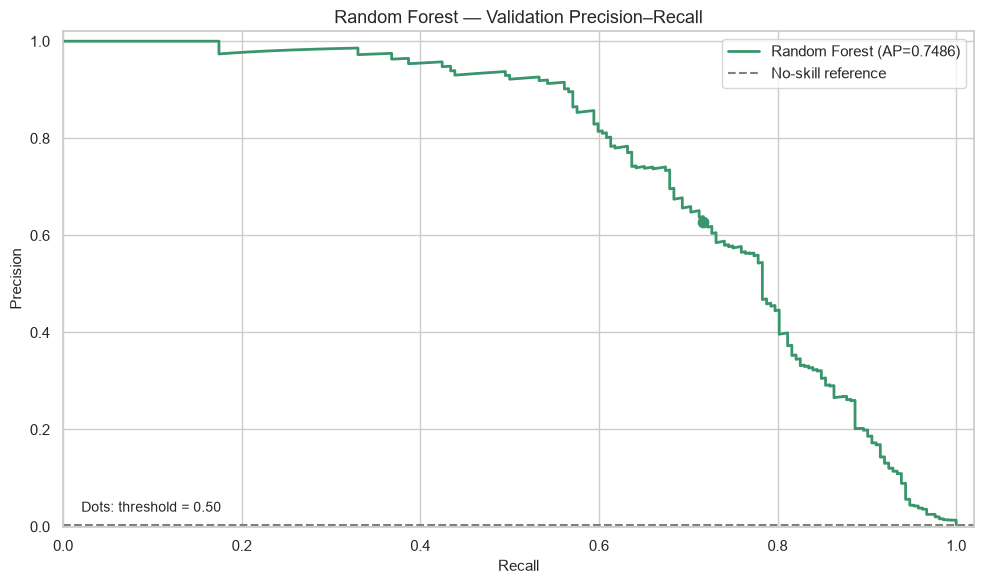

In [409]:
plot_model_pr(['Random Forest'], 'random_forest_pr.png')


## 13. XGBoost


In [410]:
time_features = ["transaction_hour", "day_of_week", "month"]
xgb_preprocessor = ColumnTransformer([
    ("numeric", clone(numeric_pipeline), NUMERIC_FEATURES + time_features),
    ("categorical", clone(categorical_pipeline), ["category", "state"]),
], sparse_threshold=0.3, verbose_feature_names_out=False)

imbalance_ratio = int((y_train == 0).sum()) / int((y_train == 1).sum())
xgb_model = XGBClassifier(
    objective="binary:logistic", n_estimators=200, learning_rate=0.03,
    max_depth=8, min_child_weight=2, subsample=0.8, colsample_bytree=0.8,
    reg_alpha=0.5, reg_lambda=5.0,  # Regularization đi kèm cây sâu hơn.
    scale_pos_weight=0.75 * imbalance_ratio,  # Tính class weight chỉ từ Train.
    eval_metric="aucpr", tree_method="hist", n_jobs=-1,
    random_state=RANDOM_STATE, verbosity=0,
)
train_and_evaluate('XGBoost', xgb_model, xgb_preprocessor)


XGBoost: AP=0.8287, fit=3.3s


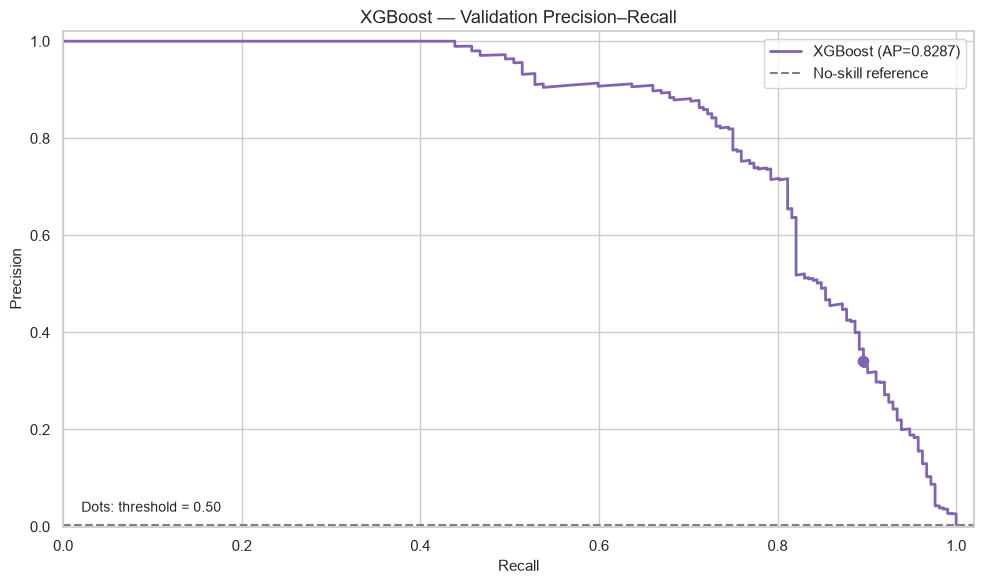

In [411]:
plot_model_pr(['XGBoost'], 'xgboost_pr.png')


## 14. Validation Model Comparison


In [412]:
expected_models = ["Logistic Regression", "Random Forest", "XGBoost"]
assert set(expected_models).issubset(model_results), "Cần chạy đủ ba model trước khi so sánh."
model_comparison_df = pd.DataFrame([model_results[name] for name in expected_models]).sort_values(
    ["Average Precision", "ROC-AUC"], ascending=False).reset_index(drop=True)

columns = ["Model", "Average Precision", "ROC-AUC", "Precision", "Recall", "F1-score"]
display(model_comparison_df[columns].rename(columns={
    metric: f"{metric} @0.50" for metric in ["Precision", "Recall", "F1-score"]
}).style.format({"Average Precision": "{:.4f}", "ROC-AUC": "{:.4f}",
                  "Precision @0.50": "{:.2%}", "Recall @0.50": "{:.2%}", "F1-score @0.50": "{:.2%}"})
  .hide(axis="index"))
model_comparison_df.to_csv(MODEL_OUTPUT_DIR / "validation_comparison.csv", index=False)


Model,Average Precision,ROC-AUC,Precision @0.50,Recall @0.50,F1-score @0.50
XGBoost,0.8287,0.9953,34.17%,89.62%,49.48%
Random Forest,0.7486,0.9876,62.81%,71.70%,66.96%
Logistic Regression,0.2382,0.9201,2.21%,83.02%,4.30%


## 15. Model Selection


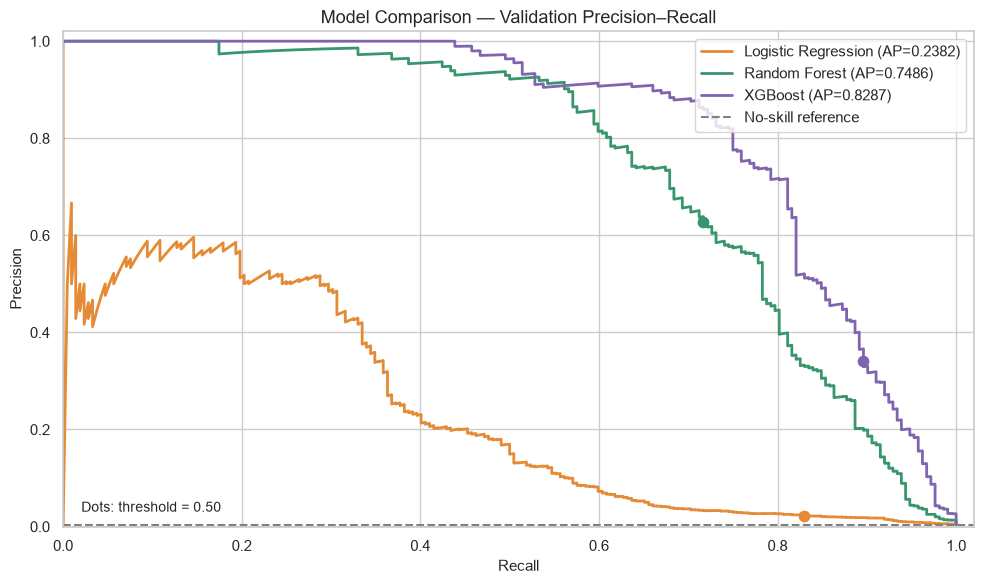

In [413]:
plot_model_pr(list(validation_probabilities), "validation_pr_comparison.png")

In [434]:
selected_model_row = model_comparison_df.iloc[0]
runner_up = model_comparison_df.iloc[1]
SELECTED_MODEL_NAME = str(selected_model_row["Model"])

print(f"Model được chọn: {SELECTED_MODEL_NAME}")



Model được chọn: XGBoost


## 16. Threshold Selection on Validation


In [415]:
def select_threshold_at_target_recall(y_true, scores, target_recall=0.80):
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    curve = pd.DataFrame({"Threshold": thresholds, "Precision": precision[:-1], "Recall": recall[:-1]})
    eligible = curve[curve["Recall"] >= target_recall]
    if eligible.empty:
        raise ValueError("Không có threshold đạt Recall mục tiêu.")
    best = eligible.sort_values(["Precision", "Threshold"], ascending=[False, False]).iloc[0]
    return float(best["Threshold"]), curve


In [416]:
TARGET_RECALL = 0.80
FINAL_MODEL_NAME = SELECTED_MODEL_NAME
final_model = trained_models[FINAL_MODEL_NAME]
scores = validation_probabilities[FINAL_MODEL_NAME]

FINAL_THRESHOLD, threshold_curve = select_threshold_at_target_recall(y_validation, scores, TARGET_RECALL)
default_result = evaluate_at_threshold(y_validation, scores, 0.50)
final_validation_result = evaluate_at_threshold(y_validation, scores, FINAL_THRESHOLD)
assert final_validation_result["Recall"] >= TARGET_RECALL


In [417]:
operating_points = pd.DataFrame([default_result, final_validation_result])
operating_points.insert(0, "Operating Point", ["Default 0.50", f"Selected: Recall >= {TARGET_RECALL:.0%}"])
columns = ["Operating Point", "Threshold", "Precision", "Recall", "F1-score",
           "True Positive", "False Positive", "False Negative"]
display(operating_points[columns].style.format({
    "Threshold": "{:.4f}", "Precision": "{:.2%}", "Recall": "{:.2%}", "F1-score": "{:.2%}",
}).hide(axis="index"))


Operating Point,Threshold,Precision,Recall,F1-score,True Positive,False Positive,False Negative
Default 0.50,0.5000,34.17%,89.62%,49.48%,190,366,22
Selected: Recall >= 80%,0.8365,71.73%,80.19%,75.72%,170,67,42


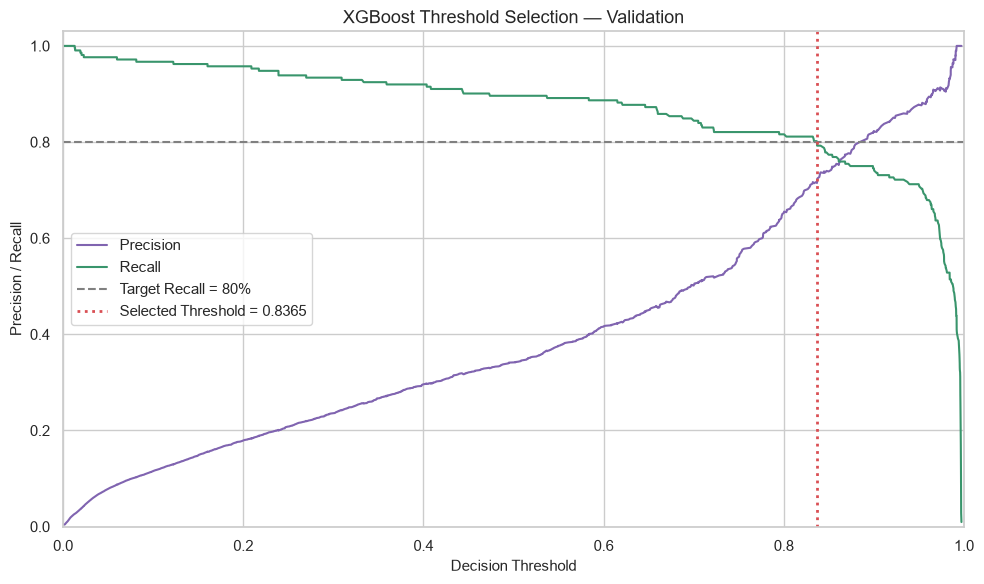

In [418]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(threshold_curve["Threshold"], threshold_curve["Precision"], label="Precision", color="#8064B0")
ax.plot(threshold_curve["Threshold"], threshold_curve["Recall"], label="Recall", color="#39956C")
ax.axhline(TARGET_RECALL, color="gray", ls="--", label=f"Target Recall = {TARGET_RECALL:.0%}")
ax.axvline(FINAL_THRESHOLD, color="#D94F54", ls=":", lw=2,
           label=f"Selected Threshold = {FINAL_THRESHOLD:.4f}")
ax.set(title=f"{FINAL_MODEL_NAME} Threshold Selection — Validation", xlabel="Decision Threshold",
       ylabel="Precision / Recall", xlim=(0, 1), ylim=(0, 1.03))
ax.legend(loc="best")
fig.tight_layout()
fig.savefig(MODEL_OUTPUT_DIR / "threshold_selection.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)


In [419]:
print(f"{FINAL_MODEL_NAME}: threshold={FINAL_THRESHOLD:.4f}; "
      f"Precision={final_validation_result['Precision']:.2%}, Recall={final_validation_result['Recall']:.2%}.")
print(f"So với 0.50: giảm {default_result['False Positive'] - final_validation_result['False Positive']} cảnh báo sai; "
      f"tăng {final_validation_result['False Negative'] - default_result['False Negative']} Fraud bị bỏ sót.")


XGBoost: threshold=0.8365; Precision=71.73%, Recall=80.19%.
So với 0.50: giảm 299 cảnh báo sai; tăng 20 Fraud bị bỏ sót.


In [420]:
import json

operating_points.to_csv(MODEL_OUTPUT_DIR / "validation_operating_points.csv", index=False)
selection = {
    "model": FINAL_MODEL_NAME, "threshold": FINAL_THRESHOLD, "target_recall": TARGET_RECALL,
    "average_precision": model_results[FINAL_MODEL_NAME]["Average Precision"],
    "validation_metrics": final_validation_result, "test_evaluated": False,
    "status": "Validation decision confirmed for Test",
}
_ = (MODEL_OUTPUT_DIR / "final_model_selection.json").write_text(
    json.dumps(selection, indent=2, ensure_ascii=False), encoding="utf-8")


## 17. Final Test Evaluation



In [421]:
# Cố định quyết định từ Validation, không chọn lại bằng Test.
LOCKED_MODEL_NAME = FINAL_MODEL_NAME
LOCKED_THRESHOLD = FINAL_THRESHOLD
assert final_model is trained_models[LOCKED_MODEL_NAME]
assert final_validation_result["Recall"] >= TARGET_RECALL


In [422]:
# 2. Dùng lại X_test, y_test đã tạo ở Feature Engineering; không fit lại preprocessing.
assert X_test.index.equals(y_test.index)
assert X_test.columns.equals(X_train.columns)

fitted_preprocessor = final_model.named_steps["preprocessor"]
processed_test_sample = fitted_preprocessor.transform(X_test.head())
assert processed_test_sample.shape[1] == len(fitted_preprocessor.get_feature_names_out())

test_summary = pd.DataFrame([summarize_split("Test", test_df)])
display(test_summary)


,Dataset,Start Date,End Date,Transactions,Dataset Share (%),Fraud,Non-Fraud,Fraud Rate (%)
0,Test,2020-10-02 20:12:08,2020-12-31 23:59:24,50942,15.0003,171,50771,0.3357


In [423]:
# 3. Dự đoán một lần và tính metric trên Test.
y_test_score = final_model.predict_proba(X_test)[:, 1]
y_test_pred = (y_test_score >= LOCKED_THRESHOLD).astype(int)

test_result = evaluate_at_threshold(y_test, y_test_score, LOCKED_THRESHOLD)
test_result["Average Precision"] = average_precision_score(y_test, y_test_score)
test_result["ROC-AUC"] = roc_auc_score(y_test, y_test_score)

In [424]:
# 4. Chuẩn bị bảng Validation–Test, dùng cùng model và threshold.
validation_result = final_validation_result.copy()
validation_result["Average Precision"] = model_results[LOCKED_MODEL_NAME]["Average Precision"]
validation_result["ROC-AUC"] = model_results[LOCKED_MODEL_NAME]["ROC-AUC"]

final_comparison = pd.DataFrame([validation_result, test_result])
final_comparison.insert(0, "Dataset", ["Validation", "Test"])
final_comparison.insert(1, "Model", LOCKED_MODEL_NAME)

final_comparison["Alerts"] = (
    final_comparison["True Positive"] + final_comparison["False Positive"]
)

In [425]:
# 5. Bảng kết quả dùng cho báo cáo.
report_columns = ["Dataset", "Average Precision", "ROC-AUC", "Precision", "Recall", "F1-score",
                  "True Positive", "False Positive", "False Negative"]
metric_formats = {"Average Precision": "{:.4f}", "ROC-AUC": "{:.4f}",
                  "Precision": "{:.2%}", "Recall": "{:.2%}", "F1-score": "{:.2%}"}
display(final_comparison[report_columns].style.format(metric_formats).hide(axis="index"))


Dataset,Average Precision,ROC-AUC,Precision,Recall,F1-score,True Positive,False Positive,False Negative
Validation,0.8287,0.9953,71.73%,80.19%,75.72%,170,67,42
Test,0.8028,0.9896,66.67%,76.02%,71.04%,130,65,41


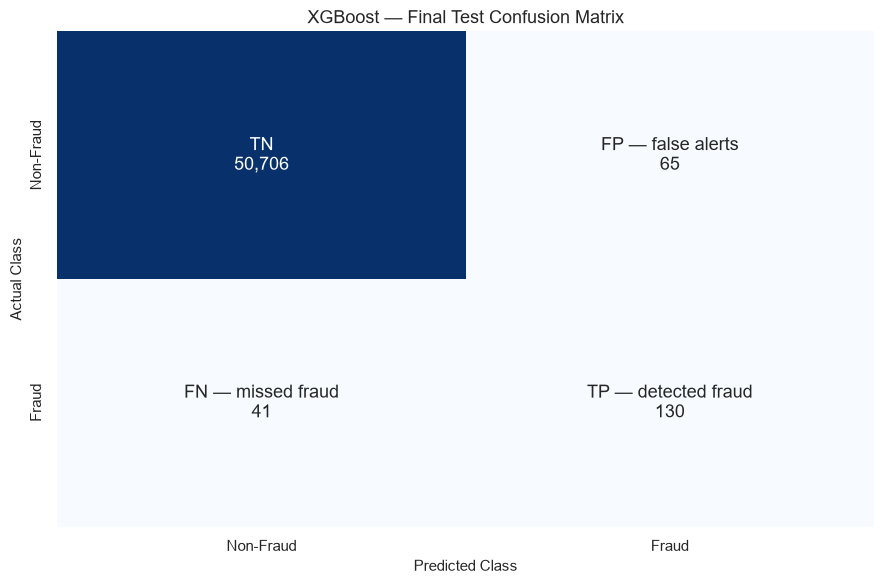

In [426]:
# 6. Confusion Matrix: hàng là nhãn thật, cột là dự đoán.
matrix = confusion_matrix(y_test, y_test_pred, labels=[0, 1])
labels = np.array([
    [f"TN\n{matrix[0, 0]:,}", f"FP — false alerts\n{matrix[0, 1]:,}"],
    [f"FN — missed fraud\n{matrix[1, 0]:,}", f"TP — detected fraud\n{matrix[1, 1]:,}"],
])
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(matrix, annot=labels, fmt="", cmap="Blues", cbar=False, annot_kws={"fontsize": 13},
            xticklabels=["Non-Fraud", "Fraud"], yticklabels=["Non-Fraud", "Fraud"], ax=ax)
ax.set(title=f"{LOCKED_MODEL_NAME} — Final Test Confusion Matrix",
       xlabel="Predicted Class", ylabel="Actual Class")
fig.tight_layout()
fig.savefig(MODEL_OUTPUT_DIR / "final_test_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)


In [433]:
# 7. Diễn giải bằng số giao dịch.
print(f"Fraud phát hiện: {test_result['True Positive']}/{int(y_test.sum())}; "
      f"cảnh báo sai: {test_result['False Positive']}; bỏ sót: {test_result['False Negative']}.")


Fraud phát hiện: 130/171; cảnh báo sai: 65; bỏ sót: 41.


In [428]:
# 8. Lưu kết quả để viết báo cáo.
test_summary.to_csv(MODEL_OUTPUT_DIR / "final_test_summary.csv", index=False)
final_comparison.to_csv(MODEL_OUTPUT_DIR / "final_validation_test_comparison.csv", index=False)
selection.update(test_evaluated=True, test_metrics=test_result,
                 status="Final Test evaluated with confirmed Validation model and threshold")
selection_path = MODEL_OUTPUT_DIR / "final_model_selection.json"
_ = selection_path.write_text(json.dumps(selection, indent=2, ensure_ascii=False), encoding="utf-8")


## 18. Demo
**Transaction → Feature Engineering → preprocessing → Fraud score → threshold → alert.**




In [429]:
# 1. Chọn giao dịch bằng score đã có, không dùng nhãn Fraud.
validation_scores = pd.Series(validation_probabilities[FINAL_MODEL_NAME], index=validation_df.index)
demo_indices = []
for alert in [True, False]:
    matching = validation_scores[(validation_scores >= FINAL_THRESHOLD) == alert]
    demo_indices.extend(matching.index[:1])
assert len(demo_indices) == 2, "Demo cần cả trường hợp có và không có cảnh báo."
demo_raw = validation_df.loc[demo_indices].drop(columns=TARGET_COL).copy()
display(demo_raw[[ID_COL, TRANSACTION_TIME_COL, "category", "amt"]])


,trans_num,trans_date_trans_time,category,amt
241043,f5a36c79c135dac1d8dd05c1b0785305,2020-06-27 20:18:28,shopping_net,934.8600
237724,6bc32af1290eb94db2dd7c0ba39ec6ef,2020-06-21 10:37:06,misc_pos,46.3700


In [430]:
# 2. Tạo features và transform bằng preprocessor đã fit trên Train.
demo_features = engineer_features(demo_raw)
demo_processed = final_model.named_steps["preprocessor"].transform(demo_features)
display(demo_features)
print(f"Input features: {demo_features.shape} → Encoded features: {demo_processed.shape}")


,log_amount,cardholder_age,log_city_population,coordinate_distance_km,category,state,transaction_hour,day_of_week,month
241043,6.8415,21.0787,6.7979,103.9184,shopping_net,WA,20,5,6
237724,3.8580,47.4738,9.1604,57.4837,misc_pos,MO,10,6,6


Input features: (2, 9) → Encoded features: (2, 34)


In [431]:
# 3. Classifier nhận dữ liệu đã preprocessing, trả score của lớp Fraud (1).
demo_scores = final_model.named_steps["classifier"].predict_proba(demo_processed)[:, 1]
demo_result = demo_raw[[ID_COL, "category", "amt"]].copy()
demo_result["Fraud Score"] = demo_scores
demo_result["Threshold"] = FINAL_THRESHOLD
demo_result["Alert"] = demo_scores >= FINAL_THRESHOLD


In [432]:
# 4. Áp dụng threshold và lưu kết quả minh họa.
demo_result["Decision"] = np.where(demo_result["Alert"], "Cần kiểm tra giao dịch", "Không phát cảnh báo")
display(demo_result.style.format({"Fraud Score": "{:.6f}", "Threshold": "{:.4f}"}).hide(axis="index"))
demo_result.to_csv(MODEL_OUTPUT_DIR / "demo_predictions.csv", index=False)


trans_num,category,amt,Fraud Score,Threshold,Alert,Decision
f5a36c79c135dac1d8dd05c1b0785305,shopping_net,934.860000,0.939311,0.8365,True,Cần kiểm tra giao dịch
6bc32af1290eb94db2dd7c0ba39ec6ef,misc_pos,46.370000,0.002588,0.8365,False,Không phát cảnh báo
